<a href="https://colab.research.google.com/github/isha0902/Deep_learning/blob/main/Lab7_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Download and extract UCI SMS Spam Collection dataset if not already present
if not os.path.exists('SMSSpamCollection'):
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
    urllib.request.urlretrieve(url, "smsspamcollection.zip")
    with zipfile.ZipFile("smsspamcollection.zip", 'r') as zip_ref:
        zip_ref.extractall(".")
    print("Dataset downloaded and extracted successfully.")

Dataset downloaded and extracted successfully.


In [2]:
# Load dataset: tab-separated with no header
df = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['label', 'text'])

# Convert labels to binary integers (ham=0, spam=1)
df['target'] = (df['label'] == 'spam').astype('int32')

# 1. Total samples and class balance
print(f"Total samples: {len(df)}\n")
class_counts = df['label'].value_counts()
class_props = df['label'].value_counts(normalize=True) * 100
print("Class Balance:")
for lbl in class_counts.index:
    print(f"  {lbl.capitalize()}: {class_counts[lbl]} ({class_props[lbl]:.2f}%)")

# 2. Message-length distribution (in words)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))
print("\nMessage Length Distribution (Word Count):")
print(f"  Min length:  {df['word_count'].min()} words")
print(f"  Max length:  {df['word_count'].max()} words")
print(f"  Mean length: {df['word_count'].mean():.2f} words")
print(f"  95th percentile: {np.percentile(df['word_count'], 95):.0f} words")

# 3. Display one example of each class
print("\nSample Messages:")
print(f"  [HAM] : {df[df['label'] == 'ham']['text'].iloc[0]}")
print(f"  [SPAM]: {df[df['label'] == 'spam']['text'].iloc[0]}")

Total samples: 5572

Class Balance:
  Ham: 4825 (86.59%)
  Spam: 747 (13.41%)

Message Length Distribution (Word Count):
  Min length:  1 words
  Max length:  171 words
  Mean length: 15.60 words
  95th percentile: 33 words

Sample Messages:
  [HAM] : Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  [SPAM]: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


In [3]:
# Hyperparameters for preprocessing
MAX_TOKENS = 10000  # Vocabulary size
MAXLEN = 60         # Justified: >99% of SMS messages are under 60 words (mean ~15.5 words)

texts = df['text'].values
labels = df['target'].values

# Stratified Split: 70% Train, 15% Validation, 15% Test
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.30, random_state=42, stratify=labels
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Initialize and adapt TextVectorization ONLY on training data
vectorize_layer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode='int',
    output_sequence_length=MAXLEN
)
vectorize_layer.adapt(X_train_raw)

# Transform raw text into padded integer sequences -> shape (N, MAXLEN)
X_train = vectorize_layer(X_train_raw).numpy()
X_val = vectorize_layer(X_val_raw).numpy()
X_test = vectorize_layer(X_test_raw).numpy()

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape} | y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape} | y_test shape:  {y_test.shape}")

X_train shape: (3900, 60) | y_train shape: (3900,)
X_val shape:   (836, 60) | y_val shape:   (836,)
X_test shape:  (836, 60) | y_test shape:  (836,)


In [4]:
EMBEDDING_DIM = 64
LSTM_UNITS = 32

model = models.Sequential([
    layers.Input(shape=(MAXLEN,), dtype='int32'),
    # Maps integer tokens (0 to MAX_TOKENS-1) to dense vectors of size EMBEDDING_DIM
    layers.Embedding(input_dim=MAX_TOKENS, output_dim=EMBEDDING_DIM, mask_zero=True),
    # Bidirectional wrapper processes sequences forward and backward, outputting 2 * LSTM_UNITS (64)
    layers.Bidirectional(layers.LSTM(LSTM_UNITS)),
    # Regularization to prevent overfitting
    layers.Dropout(0.5),
    # Binary classification output: 1 unit with sigmoid activation
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()
print("\nNote: The Bidirectional layer outputs 64 features (2 x 32 units) because it concatenates the final hidden states of both the forward LSTM (32) and backward LSTM (32).")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 60, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 664,897 (2.54 MB)

 Trainable params: 664,897 (2.54 MB)

 Non-trainable params: 0 (0.00 B)


Note: The Bidirectional layer outputs 64 features (2 x 32 units) because it concatenates the final hidden states of both the forward LSTM (32) and backward LSTM (32).


Epoch 1/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.9131 - loss: 0.2963 - val_accuracy: 0.9773 - val_loss: 0.0858
Epoch 2/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9897 - loss: 0.0460 - val_accuracy: 0.9856 - val_loss: 0.0553
Epoch 3/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.9972 - loss: 0.0176 - val_accuracy: 0.9856 - val_loss: 0.0528
Epoch 4/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - accuracy: 0.9979 - loss: 0.0095 - val_accuracy: 0.9880 - val_loss: 0.0416
Epoch 5/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 0.9892 - val_loss: 0.0560
Epoch 6/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.9880 - val_loss: 0.0584
Epoch 7/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.9880 - val_loss: 0.0623


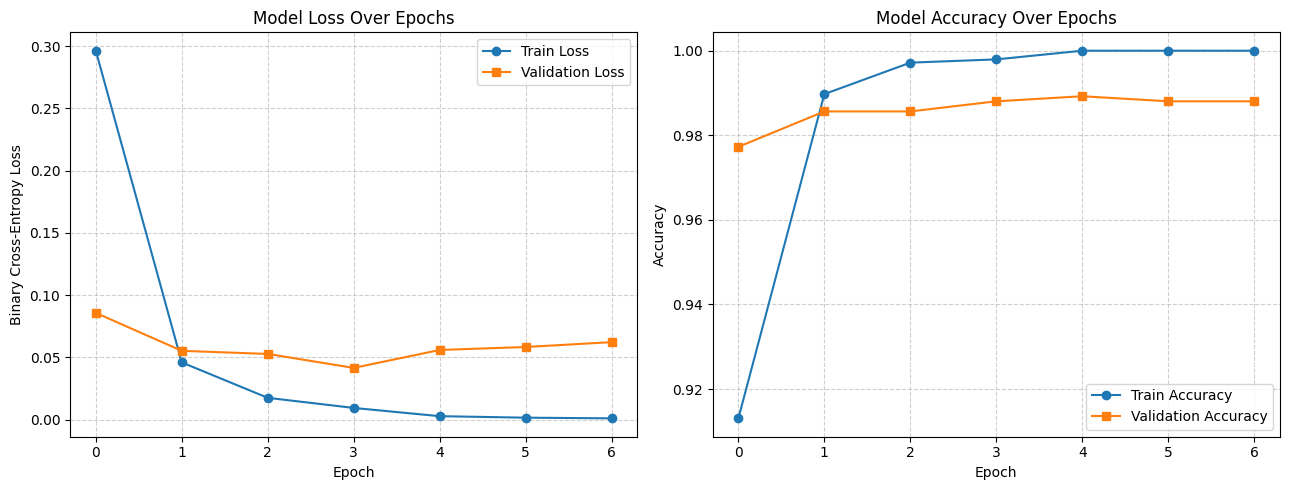


Test Accuracy: 98.68%

Classification Report:
              precision    recall  f1-score   support

     Ham (0)       0.99      0.99      0.99       724
    Spam (1)       0.95      0.95      0.95       112

    accuracy                           0.99       836
   macro avg       0.97      0.97      0.97       836
weighted avg       0.99      0.99      0.99       836



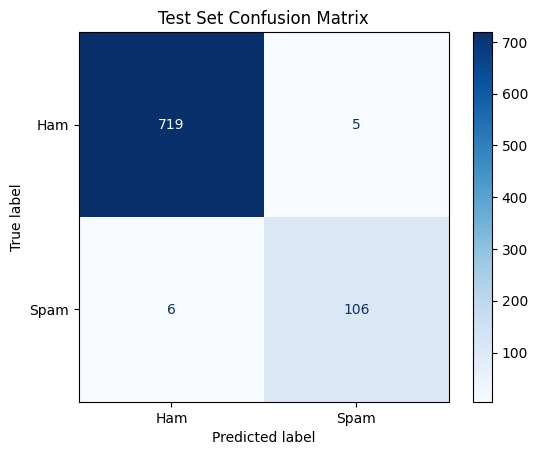

In [5]:
# Optional enhancement: EarlyStopping to prevent overfitting and restore best weights
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Plot Training vs. Validation Loss and Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Loss Curve
ax1.plot(history.history['loss'], label='Train Loss', marker='o')
ax1.plot(history.history['val_loss'], label='Validation Loss', marker='s')
ax1.set_title('Model Loss Over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Binary Cross-Entropy Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Accuracy Curve
ax2.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s')
ax2.set_title('Model Accuracy Over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Evaluate on Test Set
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")

# Predictions & Imbalanced Data Metrics
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = (y_pred_probs >= 0.5).astype('int32')

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Ham (0)', 'Spam (1)']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
disp.plot(cmap='Blues')
plt.title('Test Set Confusion Matrix')
plt.show()

In [6]:
def predict_message(text):
    # Vectorize and pad the single input string
    seq = vectorize_layer(tf.constant([text]))
    prob = model.predict(seq, verbose=0)[0][0]

    if prob >= 0.5:
        label = "Spam"
        confidence = prob
    else:
        label = "Ham"
        confidence = 1.0 - prob

    print(f"Message: \"{text}\"")
    print(f"Prediction: {label} (Spam probability: {prob:.4f} | Confidence: {confidence:.2%})\n")

# Test on 5 custom messages (clear spam, clear ham, and tricky edge cases)
sample_messages = [
    "URGENT! You have won a FREE Rs. 50,000 Amazon voucher. Click http://bit.ly/claim-now to redeem before midnight!",
    "Hey, are we still meeting at the library at 4 PM for the Deep Learning lab prep?",
    "Congratulations! Your mobile number has been selected for a cash prize of £1000. Text WIN to 80085 now.",
    "Mom asked me to remind you to pick up milk and bread on your way home.",
    "Your bank account verification is pending. Please reply with your OTP to avoid service suspension."  # Tricky/phishing-style message
]

for msg in sample_messages:
    predict_message(msg)

Message: "URGENT! You have won a FREE Rs. 50,000 Amazon voucher. Click http://bit.ly/claim-now to redeem before midnight!"
Prediction: Spam (Spam probability: 0.9953 | Confidence: 99.53%)

Message: "Hey, are we still meeting at the library at 4 PM for the Deep Learning lab prep?"
Prediction: Ham (Spam probability: 0.0001 | Confidence: 99.99%)

Message: "Congratulations! Your mobile number has been selected for a cash prize of £1000. Text WIN to 80085 now."
Prediction: Spam (Spam probability: 0.9978 | Confidence: 99.78%)

Message: "Mom asked me to remind you to pick up milk and bread on your way home."
Prediction: Ham (Spam probability: 0.0003 | Confidence: 99.97%)

Message: "Your bank account verification is pending. Please reply with your OTP to avoid service suspension."
Prediction: Spam (Spam probability: 0.9522 | Confidence: 95.22%)



(a) Why padding is needed: Neural networks process inputs in fixed-size matrix batches ((batch_size, maxlen)), whereas SMS messages vary in word count. Padding standardizes sequence lengths so matrix operations can run efficiently in parallel.  

(b) Why embeddings beat one-hot: One-hot vectors are high-dimensional ($V \approx 10,000$), sparse, and treat all words as orthogonal (no notion of similarity). Embeddings map words into a compact, dense vector space ($d = 64$) where semantically similar words (e.g., "free", "win", "prize") cluster together.

(c) Why bidirectional helps: A standard LSTM only reads left-to-right, missing context from words appearing later in a sentence. A Bidirectional LSTM processes the text both forward and backward, allowing the model to understand the full surrounding context of each word.

(d) Output layer & loss choice: Because spam detection is a binary classification problem (0 or 1), a single output neuron with sigmoid activation outputs a probability between $0$ and $1$, paired with binary_crossentropy loss.  

(e) Why accuracy is misleading on imbalanced data: Roughly 86.6% of the dataset is Ham and only 13.4% is Spam. A naive model predicting "Ham" for every message would achieve 86.6% accuracy while catching 0% of spam. Precision, Recall, F1-score, and the Confusion Matrix directly measure how well the model detects the minority Spam class without flagging legitimate messages